# Contado o crédito: cálculos y verificación

Cálculos que respaldan la guía de CarON [*Contado o crédito: cómo la forma de pago cambia qué auto conviene*](https://www.caron.cl/guias/como-el-credito-cambia-que-auto-conviene). El objetivo es documentar cómo se obtiene cada cifra publicada y permitir verificarla de forma independiente.

**Contenido**

1. Modelo de crédito: tasa mensual, cuota, intereses y saldo.
2. Datos del ejemplo y costo total por forma de pago.
3. Sensibilidad de los intereses al CAE y al plazo.
4. Costo de prepagar el crédito y CAE de equilibrio con el bono.
5. Bono con el que cambia el orden entre los dos autos.
6. Verificación de las cifras citadas en la guía.

**Supuestos**

- Crédito en pesos, no reajustable, de cuotas fijas (amortización francesa) y pagos mensuales.
- El CAE se usa como tasa anual efectiva. El CAE real incluye además gastos y seguros, por lo que el modelo es una aproximación.
- No se incluyen seguros, impuesto de timbres y estampillas, gastos operacionales, costo de oportunidad del dinero ni inflación.
- Los dos autos son ficticios, con valores redondos.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

# Guarda cada gráfico interactivo y además como PNG, para que se vea en GitHub
pio.renderers.default = "plotly_mimetype+png"

VIOLETA = "#8B5CF6"
GRIS = "#94a3b8"
TINTA = "#334155"


def pesos(x):
    # Formato chileno: punto como separador de miles
    return "$" + f"{x:,.0f}".replace(",", ".")


def millones(x, decimales=1):
    unidad = "millón" if round(x / 1e6, decimales) == 1 else "millones"
    return "$" + f"{x / 1e6:.{decimales}f}".replace(".", ",") + " " + unidad


def porcentaje(x, decimales=2):
    return f"{x:.{decimales}%}".replace(".", ",")


def estilo(fig, titulo, eje_x, eje_y):
    fig.update_layout(
        title=titulo,
        template="plotly_white",
        font=dict(color=TINTA),
        xaxis_title=eje_x,
        yaxis_title=eje_y,
        hovermode="x unified",
        margin=dict(t=70, r=30, b=60, l=80),
        separators=",.",  # decimal con coma y miles con punto
        width=900,
        height=450,
    )
    return fig

## 1. Modelo de crédito

Tasa mensual equivalente al CAE, es decir, la que capitalizada 12 veces da el CAE:

$$ i = (1 + \text{CAE})^{1/12} - 1 $$

Cuota fija de un crédito por un monto $P$ a $n$ meses:

$$ C = P \cdot \frac{i}{1 - (1 + i)^{-n}} $$

Intereses totales:

$$ I = nC - P $$

Saldo de capital después de pagar $k$ cuotas:

$$ S_k = P(1+i)^k - C \cdot \frac{(1+i)^k - 1}{i} $$

In [2]:
def tasa_mensual(cae):
    return (1 + cae) ** (1 / 12) - 1


def cuota(monto, cae, meses):
    i = tasa_mensual(cae)
    return monto * i / (1 - (1 + i) ** -meses)


def intereses(monto, cae, meses):
    return cuota(monto, cae, meses) * meses - monto


def saldo(monto, cae, meses, pagadas):
    i = tasa_mensual(cae)
    c = cuota(monto, cae, meses)
    return monto * (1 + i) ** pagadas - c * ((1 + i) ** pagadas - 1) / i


print("Tasa mensual con CAE 15%:", porcentaje(tasa_mensual(0.15), 4))

Tasa mensual con CAE 15%: 1,1715%


**Control del modelo:** la fórmula cerrada del saldo se compara con una tabla de amortización calculada mes a mes. El saldo al final del plazo debe ser cero.

In [3]:
def tabla_amortizacion(monto, cae, meses):
    i = tasa_mensual(cae)
    c = cuota(monto, cae, meses)
    filas, s = [], monto
    for mes in range(1, meses + 1):
        interes = s * i
        amortizacion = c - interes
        s -= amortizacion
        filas.append((mes, c, interes, amortizacion, s))
    return pd.DataFrame(filas, columns=["mes", "cuota", "interés", "amortización", "saldo"]).set_index("mes")


t = tabla_amortizacion(10e6, 0.15, 60)
for k in (1, 12, 30, 59):
    assert abs(t.loc[k, "saldo"] - saldo(10e6, 0.15, 60, k)) < 1e-6
assert abs(t.loc[60, "saldo"]) < 1e-6
assert abs(t["interés"].sum() - intereses(10e6, 0.15, 60)) < 1e-6
print("Fórmulas cerradas coinciden con la tabla de amortización.")
t.head(3).style.format(pesos)

Fórmulas cerradas coinciden con la tabla de amortización.


,cuota,interés,amortización,saldo
mes,,,,
1,$232.983,$117.149,$115.834,$9.884.166
2,$232.983,$115.792,$117.191,$9.766.976
3,$232.983,$114.419,$118.563,$9.648.412


## 2. Datos del ejemplo y costo total por forma de pago

| Auto | Precio al contado | Bono por financiar | Precio con crédito |
| ---- | ----------------: | -----------------  | -----------------: |
| A    | $30.000.000       | $1.000.000         | $29.000.000        |
| B    | $32.000.000       | $2.700.000         | $29.300.000        |

El precio con crédito es el precio al contado menos el bono, que solo se aplica si se financia con la automotora.

Condiciones del crédito: **pie de 20% del precio con crédito, 60 cuotas, CAE de 15%.**

In [4]:
PIE = 0.20
MESES = 60
CAE = 0.15

autos = pd.DataFrame(
    {"precio_contado": [30_000_000, 32_000_000], "bono": [1_000_000, 2_700_000]},
    index=pd.Index(["Auto A", "Auto B"], name="auto"),
)
autos["precio_credito"] = autos.precio_contado - autos.bono
autos["pie"] = autos.precio_credito * PIE
autos["financiado"] = autos.precio_credito - autos.pie
autos["cuota"] = cuota(autos.financiado, CAE, MESES)
autos["intereses"] = intereses(autos.financiado, CAE, MESES)
autos["total_credito"] = autos.precio_credito + autos.intereses

a, b = autos.loc["Auto A"], autos.loc["Auto B"]
autos.T.style.format(pesos)

auto,Auto A,Auto B
precio_contado,$30.000.000,$32.000.000
bono,$1.000.000,$2.700.000
precio_credito,$29.000.000,$29.300.000
pie,$5.800.000,$5.860.000
financiado,$23.200.000,$23.440.000
cuota,$540.520,$546.112
intereses,$9.231.205,$9.326.700
total_credito,$38.231.205,$38.626.700


Costo total de cada auto según la forma de pago, y diferencia entre ambos:

- **Al contado:** precio al contado.
- **Con crédito a término:** pie más las 60 cuotas, es decir, precio con crédito más intereses.

In [5]:
costos = pd.DataFrame({
    "Al contado": autos.precio_contado,
    "Precio con crédito": autos.precio_credito,
    "Con crédito a término": autos.total_credito,
})
costos.loc["B − A"] = costos.loc["Auto B"] - costos.loc["Auto A"]
costos.style.format(pesos)

,Al contado,Precio con crédito,Con crédito a término
auto,,,
Auto A,$30.000.000,$29.000.000,$38.231.205
Auto B,$32.000.000,$29.300.000,$38.626.700
B − A,$2.000.000,$300.000,$395.495


In [6]:
print("Diferencia de cuota (B − A):", pesos(b.cuota - a.cuota))
print("Intereses del Auto A / precio al contado:", porcentaje(a.intereses / a.precio_contado, 1))

Diferencia de cuota (B − A): $5.592
Intereses del Auto A / precio al contado: 30,8%


## 3. Sensibilidad de los intereses al CAE y al plazo

Con el monto financiado del Auto A se varía un parámetro a la vez:

- CAE de 12% y de 18%, con 60 cuotas.
- 48 y 60 cuotas, con CAE de 15%.

Las variaciones se comparan con el bono del Auto A.

In [7]:
fin_a = a.financiado

sensibilidad = pd.DataFrame({
    "caso": ["CAE 12%, 60 cuotas", "CAE 18%, 60 cuotas", "CAE 15%, 48 cuotas", "CAE 15%, 60 cuotas"],
    "cuota": [cuota(fin_a, 0.12, 60), cuota(fin_a, 0.18, 60), cuota(fin_a, 0.15, 48), cuota(fin_a, 0.15, 60)],
    "intereses": [intereses(fin_a, 0.12, 60), intereses(fin_a, 0.18, 60), intereses(fin_a, 0.15, 48), intereses(fin_a, 0.15, 60)],
}).set_index("caso")

efecto_cae = sensibilidad.loc["CAE 18%, 60 cuotas", "intereses"] - sensibilidad.loc["CAE 12%, 60 cuotas", "intereses"]
efecto_plazo = sensibilidad.loc["CAE 15%, 60 cuotas", "intereses"] - sensibilidad.loc["CAE 15%, 48 cuotas", "intereses"]
sube_cuota_48 = sensibilidad.loc["CAE 15%, 48 cuotas", "cuota"] - sensibilidad.loc["CAE 15%, 60 cuotas", "cuota"]

print("Efecto de subir el CAE de 12% a 18%:", pesos(efecto_cae))
print("Efecto de pasar de 48 a 60 cuotas:  ", pesos(efecto_plazo))
print("Aumento de cuota al pasar a 48:      ", pesos(sube_cuota_48))
sensibilidad.style.format(pesos)

Efecto de subir el CAE de 12% a 18%: $3.810.886
Efecto de pasar de 48 a 60 cuotas:   $1.968.087
Aumento de cuota al pasar a 48:       $94.128


,cuota,intereses
caso,,
"CAE 12%, 60 cuotas",$508.908,$7.334.489
"CAE 18%, 60 cuotas",$572.423,$11.145.375
"CAE 15%, 48 cuotas",$634.648,$7.263.118
"CAE 15%, 60 cuotas",$540.520,$9.231.205


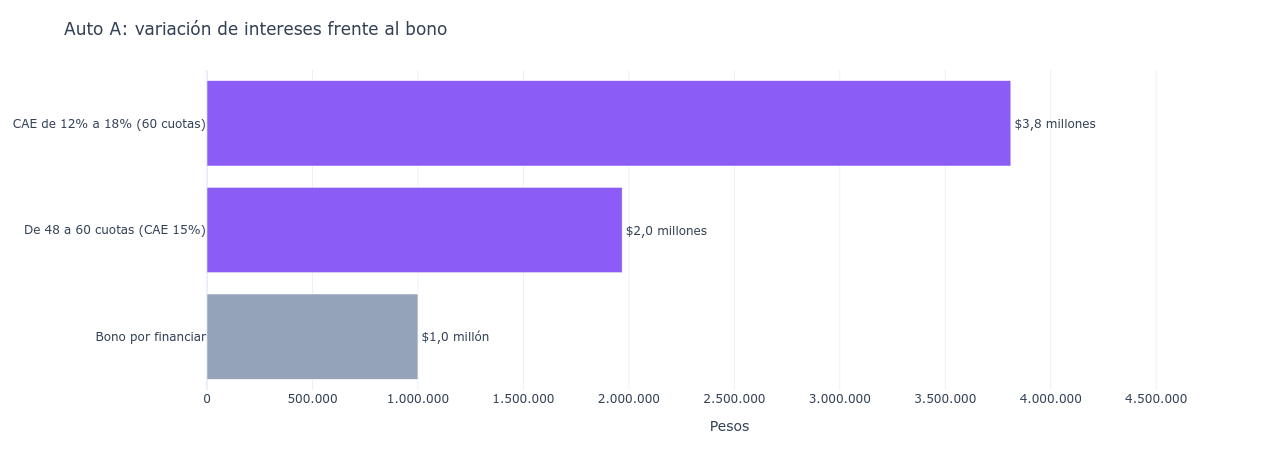

In [8]:
fig = go.Figure(go.Bar(
    x=[efecto_cae, efecto_plazo, a.bono],
    y=["CAE de 12% a 18% (60 cuotas)", "De 48 a 60 cuotas (CAE 15%)", "Bono por financiar"],
    orientation="h",
    marker_color=[VIOLETA, VIOLETA, GRIS],
    text=[millones(v) for v in (efecto_cae, efecto_plazo, a.bono)],
    textposition="outside",
    hovertemplate="%{y}: %{text}<extra></extra>",
))
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(range=[0, efecto_cae * 1.3], tickformat=",.0f")
estilo(fig, "Auto A: variación de intereses frente al bono", "Pesos", None).update_layout(hovermode="closest")

Intereses totales del Auto A como función continua del CAE, a 48 y 60 cuotas:

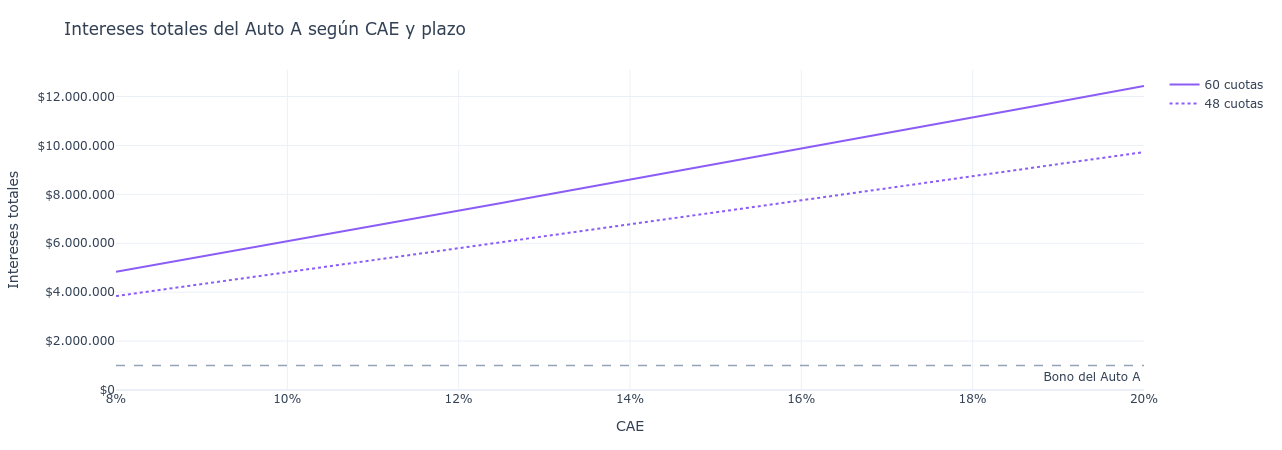

In [9]:
caes = np.linspace(0.08, 0.20, 49)

fig = go.Figure()
for meses, dash in [(60, "solid"), (48, "dot")]:
    fig.add_scatter(
        x=caes, y=intereses(fin_a, caes, meses), name=f"{meses} cuotas",
        line=dict(color=VIOLETA, width=2, dash=dash),
        hovertemplate="%{y:$,.0f}",
    )
fig.add_hline(y=a.bono, line=dict(color=GRIS, dash="dash", width=1.5),
              annotation_text="Bono del Auto A", annotation_position="bottom right")
fig.update_xaxes(tickformat=".0%")
fig.update_yaxes(tickformat="$,.0f", rangemode="tozero")
estilo(fig, "Intereses totales del Auto A según CAE y plazo", "CAE", "Intereses totales")

## 4. Costo de prepagar el crédito

Ley 18.010, artículo 10: las operaciones de crédito de dinero de hasta 5.000 UF se pueden prepagar sin consentimiento del acreedor. En operaciones no reajustables, la comisión de prepago tiene un tope de un mes de intereses pactados sobre el capital que se prepaga. El modelo usa ese tope.

Costo de tomar el crédito y prepagarlo después de $k$ cuotas:

$$ \text{costo}(k) = kC + S_k (1 + i) - P $$

Es decir, las cuotas pagadas, más el saldo, más la comisión $S_k \cdot i$, menos el monto financiado. Financiar para obtener el bono y prepagar conviene si $\text{bono} > \text{costo}(k)$.

El **CAE de equilibrio** es el CAE con el que $\text{costo}(k) = \text{bono}$. Se obtiene por bisección, porque el costo es creciente en el CAE.

In [10]:
def costo_prepago(monto, cae, meses, pagadas):
    s = saldo(monto, cae, meses, pagadas)
    comision = s * tasa_mensual(cae)
    return cuota(monto, cae, meses) * pagadas + s + comision - monto


def cae_equilibrio(monto, bono, meses, pagadas, bajo=0.0001, alto=0.60):
    if costo_prepago(monto, bajo, meses, pagadas) > bono:
        return None  # el bono no cubre el costo ni con CAE casi cero
    for _ in range(80):
        medio = (bajo + alto) / 2
        if costo_prepago(monto, medio, meses, pagadas) > bono:
            alto = medio
        else:
            bajo = medio
    return medio


# Control: con 0 cuotas pagadas, el costo es solo la comisión sobre el monto completo
assert abs(costo_prepago(10e6, 0.15, 60, 0) - 10e6 * tasa_mensual(0.15)) < 1e-6

prepago = pd.DataFrame({
    "financiado": autos.financiado,
    "bono": autos.bono,
    "costo prepago 12 meses (CAE 15%)": [costo_prepago(f, CAE, MESES, 12) for f in autos.financiado],
    "CAE de equilibrio": [cae_equilibrio(f, bo, MESES, 12) for f, bo in zip(autos.financiado, autos.bono)],
})
prepago.style.format(pesos, subset=["financiado", "bono", "costo prepago 12 meses (CAE 15%)"]).format(porcentaje, subset=["CAE de equilibrio"])

,financiado,bono,costo prepago 12 meses (CAE 15%),CAE de equilibrio
auto,,,,
Auto A,$23.200.000,$1.000.000,$3.276.796,"4,47%"
Auto B,$23.440.000,$2.700.000,$3.310.694,"12,15%"


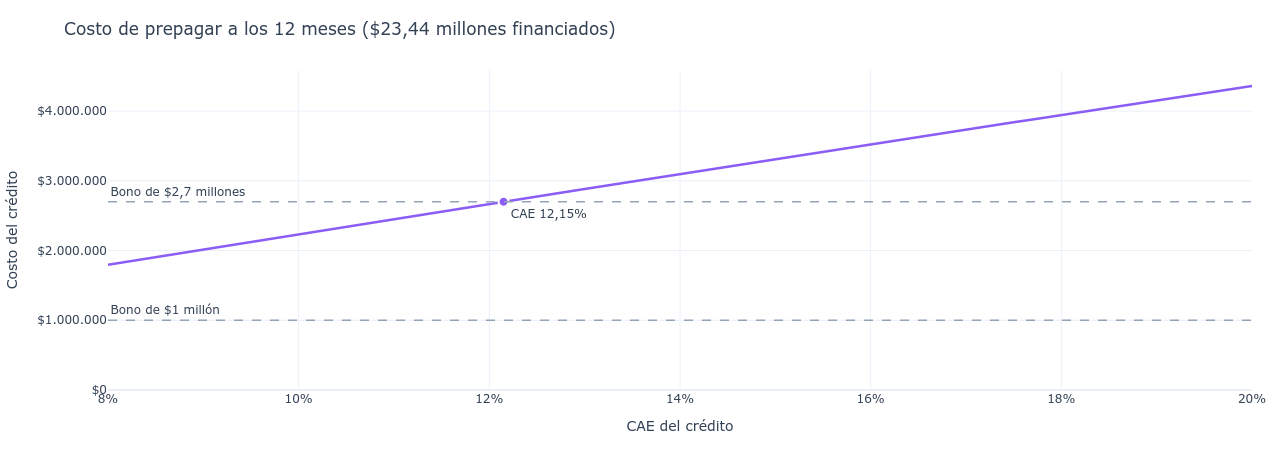

In [11]:
fin_b = b.financiado
eq_b = cae_equilibrio(fin_b, b.bono, MESES, 12)

fig = go.Figure()
fig.add_scatter(x=caes, y=costo_prepago(fin_b, caes, MESES, 12), name="Costo del crédito", showlegend=False,
                line=dict(color=VIOLETA, width=2.5), hovertemplate="%{y:$,.0f}")
for bono, etiqueta in [(b.bono, "Bono de $2,7 millones"), (a.bono, "Bono de $1 millón")]:
    fig.add_hline(y=bono, line=dict(color=GRIS, dash="dash", width=1.5),
                  annotation_text=etiqueta, annotation_position="top left")
fig.add_scatter(x=[eq_b], y=[b.bono], mode="markers+text", text=["CAE " + porcentaje(eq_b)],
                textposition="bottom right", marker=dict(color=VIOLETA, size=10, line=dict(color="white", width=2)),
                showlegend=False, hoverinfo="skip")
fig.update_xaxes(tickformat=".0%")
fig.update_yaxes(tickformat="$,.0f", rangemode="tozero")
estilo(fig, f"Costo de prepagar a los 12 meses ({millones(fin_b, 2)} financiados)",
       "CAE del crédito", "Costo del crédito")

### Sensibilidad al mes de prepago

Resultado neto (bono − costo) para el Auto B según el CAE y el número de cuotas pagadas antes de prepagar. La línea marca el punto de equilibrio: bajo ella, el bono supera el costo.

El modelo no considera condiciones comerciales como un mínimo de cuotas exigido para mantener el bono.

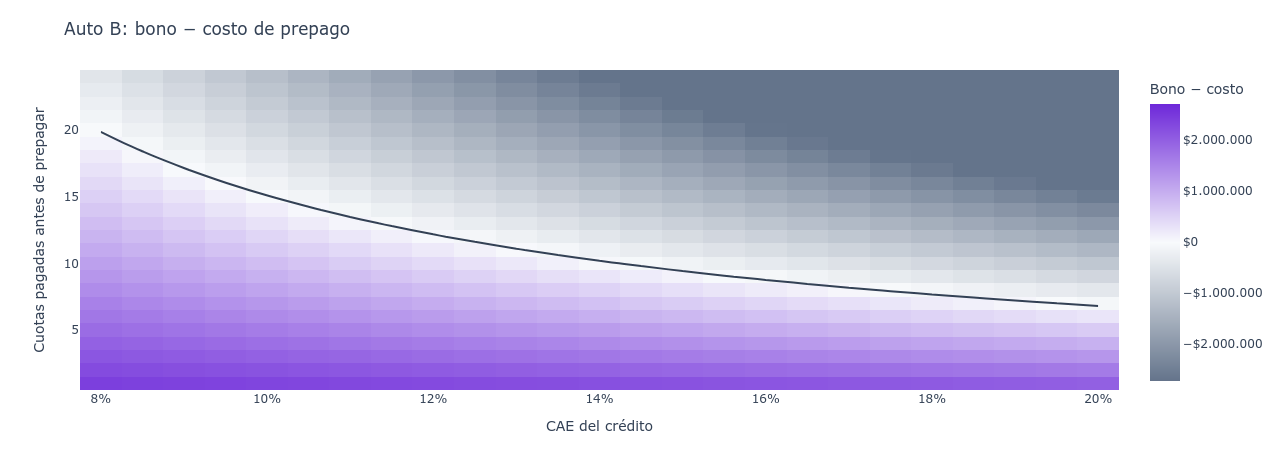

In [12]:
meses_prepago = np.arange(1, 25)
caes_mapa = np.arange(0.08, 0.2001, 0.005)
neto = np.array([[b.bono - costo_prepago(fin_b, c, MESES, k) for c in caes_mapa] for k in meses_prepago])

fig = go.Figure(go.Heatmap(
    x=caes_mapa, y=meses_prepago, z=neto,
    zmid=0, zmin=-b.bono, zmax=b.bono, colorscale=[[0, "#64748b"], [0.5, "#f8fafc"], [1, "#6D28D9"]],
    colorbar=dict(title="Bono − costo", tickformat="$,.0f"),
    hovertemplate="CAE %{x:.1%} · prepago tras %{y} cuotas<br>Neto: %{z:$,.0f}<extra></extra>",
))
fig.add_contour(x=caes_mapa, y=meses_prepago, z=neto, showscale=False,
                contours=dict(start=0, end=0, size=1, coloring="none"),
                line=dict(color=TINTA, width=2), hoverinfo="skip")
fig.update_xaxes(tickformat=".0%")
estilo(fig, "Auto B: bono − costo de prepago", "CAE del crédito", "Cuotas pagadas antes de prepagar").update_layout(hovermode="closest")

## 5. Bono con el que cambia el orden entre los dos autos

Si ambos créditos tienen el mismo pie porcentual $p$, plazo y CAE, el total pagado con crédito es proporcional al precio con crédito $Q$:

$$ \text{total} = pQ + nC = Q \left[ p + (1-p) \cdot \frac{n\,i}{1 - (1+i)^{-n}} \right] $$

Por lo tanto, con crédito el orden entre los autos lo determina $Q$ y el CAE solo escala la diferencia. B es más barato que A si y solo si $Q_B < Q_A$, es decir:

$$ \text{bono}_B > (\text{contado}_B - \text{contado}_A) + \text{bono}_A $$

Este umbral no depende del CAE. Al contado el bono no se aplica, y la diferencia es siempre la de los precios al contado.

**Control:** se calcula el umbral numéricamente, por bisección sobre el bono de B, para varios CAE, y se compara con la expresión cerrada.

In [13]:
def total_credito(precio_contado, bono, cae=CAE, meses=MESES):
    precio = precio_contado - bono
    return precio + intereses(precio * (1 - PIE), cae, meses)


def bono_umbral_b(cae):
    total_a = total_credito(a.precio_contado, a.bono, cae)
    bajo, alto = 0.0, float(b.precio_contado)
    for _ in range(80):
        medio = (bajo + alto) / 2
        if total_credito(b.precio_contado, medio, cae) > total_a:
            bajo = medio
        else:
            alto = medio
    return medio


umbral_cerrado = (b.precio_contado - a.precio_contado) + a.bono
for cae in np.arange(0.06, 0.301, 0.02):
    assert abs(bono_umbral_b(cae) - umbral_cerrado) < 1
print("Umbral de bono para B (cualquier CAE):", pesos(umbral_cerrado))

Umbral de bono para B (cualquier CAE): $3.000.000


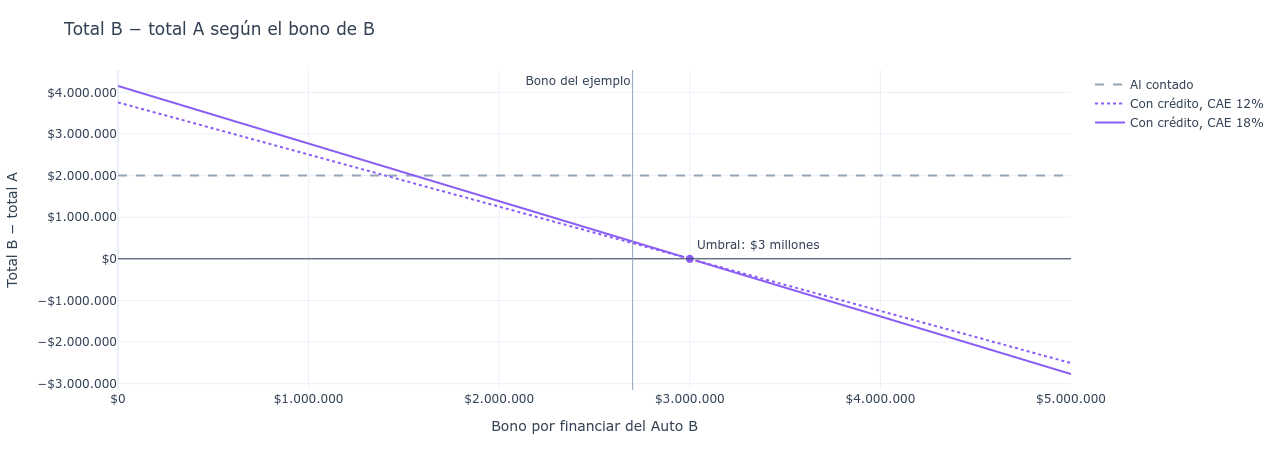

In [14]:
bonos_b = np.linspace(0, 5_000_000, 51)

fig = go.Figure()
fig.add_scatter(x=bonos_b, y=np.full_like(bonos_b, b.precio_contado - a.precio_contado), name="Al contado",
                line=dict(color=GRIS, width=2, dash="dash"), hovertemplate="%{y:$,.0f}")
for cae, dash in [(0.12, "dot"), (0.18, "solid")]:
    fig.add_scatter(x=bonos_b, y=total_credito(b.precio_contado, bonos_b, cae) - total_credito(a.precio_contado, a.bono, cae),
                    name=f"Con crédito, CAE {cae:.0%}", line=dict(color=VIOLETA, width=2, dash=dash),
                    hovertemplate="%{y:$,.0f}")
fig.add_hline(y=0, line=dict(color=TINTA, width=1))
fig.add_vline(x=b.bono, line=dict(color=GRIS, width=1), annotation_text="Bono del ejemplo", annotation_position="top left")
fig.add_scatter(x=[umbral_cerrado], y=[0], mode="markers+text", text=["Umbral: " + millones(umbral_cerrado, 0)],
                textposition="top right", marker=dict(color=VIOLETA, size=10, line=dict(color="white", width=2)),
                showlegend=False, hoverinfo="skip")
fig.update_xaxes(tickformat="$,.0f")
fig.update_yaxes(tickformat="$,.0f")
estilo(fig, "Total B − total A según el bono de B", "Bono por financiar del Auto B", "Total B − total A")

El resultado deja de valer si los créditos de cada auto tienen distinto CAE, plazo o pie. En ese caso hay que comparar los totales completos.

## 6. Verificación de las cifras citadas en la guía

Cada fila es una cifra publicada en la guía, con el valor calculado en este notebook. Para las cifras que la guía redondea ("unos", "casi", "más o menos") la tolerancia es explícita.

In [15]:
verificacion = pd.DataFrame([
    # (cifra en la guía, valor publicado, valor calculado, tolerancia)
    ("Cuota mensual, Auto A", 540_520, a.cuota, 0.5),
    ("Cuota mensual, Auto B", 546_112, b.cuota, 0.5),
    ("Intereses en 60 meses, Auto A", 9_231_205, a.intereses, 0.5),
    ("Intereses en 60 meses, Auto B", 9_326_700, b.intereses, 0.5),
    ("Diferencia al contado (B − A)", 2_000_000, b.precio_contado - a.precio_contado, 0),
    ("Diferencia de precio con crédito (B − A)", 300_000, b.precio_credito - a.precio_credito, 0),
    ("Diferencia de cuota: unos 5 mil", 5_000, b.cuota - a.cuota, 1_000),
    ("Intereses Auto A, CAE 12%: unos 7,3 millones", 7_300_000, sensibilidad.loc["CAE 12%, 60 cuotas", "intereses"], 50_000),
    ("Intereses Auto A, CAE 18%: unos 11,1 millones", 11_100_000, sensibilidad.loc["CAE 18%, 60 cuotas", "intereses"], 50_000),
    ("Efecto CAE 12% → 18% (gráfico): 3,8 millones", 3_800_000, efecto_cae, 50_000),
    ("Efecto 48 → 60 cuotas (gráfico): 2,0 millones", 2_000_000, efecto_plazo, 50_000),
    ("Aumento de cuota a 48 meses: unos 94 mil", 94_000, sube_cuota_48, 1_000),
    ("Monto financiado en el gráfico de prepago: unos 23 millones", 23_000_000, fin_b, 500_000),
    ("CAE de equilibrio, bono 2,7 millones: más o menos 12%", 0.12, eq_b, 0.005),
], columns=["cifra en la guía", "publicado", "calculado", "tolerancia"])
verificacion["cumple"] = (verificacion.calculado - verificacion.publicado).abs() <= verificacion.tolerancia

assert verificacion.cumple.all(), verificacion[~verificacion.cumple]
verificacion.style.format(lambda x: porcentaje(x) if abs(x) < 1 else pesos(x), subset=["publicado", "calculado", "tolerancia"])

,cifra en la guía,publicado,calculado,tolerancia,cumple
0,"Cuota mensual, Auto A",$540.520,$540.520,"50,00%",True
1,"Cuota mensual, Auto B",$546.112,$546.112,"50,00%",True
2,"Intereses en 60 meses, Auto A",$9.231.205,$9.231.205,"50,00%",True
3,"Intereses en 60 meses, Auto B",$9.326.700,$9.326.700,"50,00%",True
4,Diferencia al contado (B − A),$2.000.000,$2.000.000,"0,00%",True
5,Diferencia de precio con crédito (B − A),$300.000,$300.000,"0,00%",True
6,Diferencia de cuota: unos 5 mil,$5.000,$5.592,$1.000,True
7,"Intereses Auto A, CAE 12%: unos 7,3 millones",$7.300.000,$7.334.489,$50.000,True
8,"Intereses Auto A, CAE 18%: unos 11,1 millones",$11.100.000,$11.145.375,$50.000,True
9,"Efecto CAE 12% → 18% (gráfico): 3,8 millones",$3.800.000,$3.810.886,$50.000,True


Afirmaciones cualitativas de la guía y su respaldo numérico:

| Afirmación en la guía | Respaldo |
| --------------------- | -------- |
| Los intereses son "casi un tercio de lo que vale el auto" | Sección 2: intereses del Auto A / precio al contado |
| La diferencia de CAE de 12% a 18% mueve "más que cualquier bono" | Sección 3: 3,8 millones, contra bonos de 1 y 2,7 millones |
| El bono de un millón "no alcanza con ningún CAE razonable" al prepagar al año | Sección 4: CAE de equilibrio del Auto A |
| El orden entre autos puede cambiar según la forma de pago | Sección 5: con un bono de B sobre el umbral, B es más barato con crédito y más caro al contado |

Los parámetros (`PIE`, `MESES`, `CAE` y la tabla `autos`) se pueden modificar para evaluar otros casos. La tabla de verificación está atada a los datos de la guía y deja de cumplirse si se cambian.

Calculadora para revisar un CAE real: [www.caron.cl/calculadora-de-cae-credito-automotriz](https://www.caron.cl/calculadora-de-cae-credito-automotriz).